<a href="https://colab.research.google.com/github/LinjetVictor/Electricity-Theft-Detection-in-Smart-Meter-Data-Using-Supervised-Machine-Learning-/blob/main/Electricity_Theft_Detection_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Electricity Theft Detection in Smart Meter Data Using Supervised Machine Learning:(SGCC dataset)

| Steps | What to do |
|---|---|
| 1 | Set up and load the data |
| 2 | Explore the data (EDA) |
| 3 | Clean the data |
| 4 | Engineer features |
| 5 | Split the data by customer |
| 6 | Train and compare models |
| 7 | Tune and evaluate |
| 8 | Explain the model |


## Step 1: Set up and load the data

In [ ]:
# Install the libraries used in this project
!pip -q install xgboost lightgbm imbalanced-learn shap kaggle

In [ ]:
import os, glob, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 50)

**Loading the Dataset**

In [ ]:
from google.colab import files
import os, shutil

print('Upload the dataset CSV file')
uploaded = files.upload()

os.makedirs('data', exist_ok=True)
for name in uploaded:
    shutil.move(name, os.path.join('data', name))

!ls -lh data

Upload the dataset CSV file


Saving data set.csv to data set.csv
total 156M
-rw-r--r-- 1 root root 156M Oct 25 11:09 'data set.csv'


In [ ]:
# Load the largest CSV in the data folder
csv_files = sorted(glob.glob('data/**/*.csv', recursive=True), key=os.path.getsize, reverse=True)
print('CSV files found:', csv_files)

df = pd.read_csv(csv_files[0])
print('Shape:', df.shape)
df.iloc[:5, :6]

CSV files found: ['data/data set.csv']
Shape: (42372, 1036)


,1/1/2014,1/2/2014,1/3/2014,1/4/2014,1/5/2014,1/6/2014
0,0.0,0.0,0.01,0.0,0.0,0.00
1,0.0,0.0,0.00,0.0,0.0,0.00
2,0.0,0.0,0.00,0.0,0.0,4.98
3,0.0,0.0,0.00,0.0,0.0,0.00
4,0.0,0.0,0.00,0.0,0.0,0.00


In [ ]:
# Separate the label, the customer ID and the daily readings.
# Date columns are parsed and sorted in time order.
LABEL = 'FLAG'
id_cols = [c for c in df.columns if c in ('CONS_NO', 'Unnamed: 0')]
date_cols = [c for c in df.columns if c not in id_cols + [LABEL]]

dates = pd.to_datetime(pd.Series(date_cols), errors='coerce')
valid = dates.notna().values
date_cols = [c for c, ok in zip(date_cols, valid) if ok]
dates = pd.DatetimeIndex(dates[valid])

order = np.argsort(dates.values)
date_cols = [date_cols[i] for i in order]
dates = dates[order]

y = df[LABEL].astype(int).values
ids = df[id_cols[0]].values if id_cols else np.arange(len(df))
X_raw = df[date_cols].apply(pd.to_numeric, errors='coerce')
X_raw.columns = dates

print('Customers:', X_raw.shape[0], '| Days:', X_raw.shape[1])
print('Date range:', dates.min().date(), 'to', dates.max().date())
print('Theft customers:', y.sum(), f'({y.mean():.1%})')

Customers: 42372 | Days: 1034
Date range: 2014-01-01 to 2016-10-31
Theft customers: 3615 (8.5%)


## Step 2: Explore the data (EDA)

In [ ]:
print('Missing values overall:', f'{X_raw.isna().mean().mean():.1%}')
miss_per_customer = X_raw.isna().mean(axis=1)
print(miss_per_customer.describe().round(3))
print('Customers with >50% missing:', (miss_per_customer > 0.5).sum())
print('Share of zero readings:', f'{(X_raw == 0).mean().mean():.1%}')
print('Negative readings:', int((X_raw < 0).sum().sum()))

Missing values overall: 25.6%
count    42372.000
mean         0.256
std          0.288
min          0.001
25%          0.013
50%          0.106
75%          0.620
max          1.000
dtype: float64
Customers with >50% missing: 11184
Share of zero readings: 13.2%
Negative readings: 0


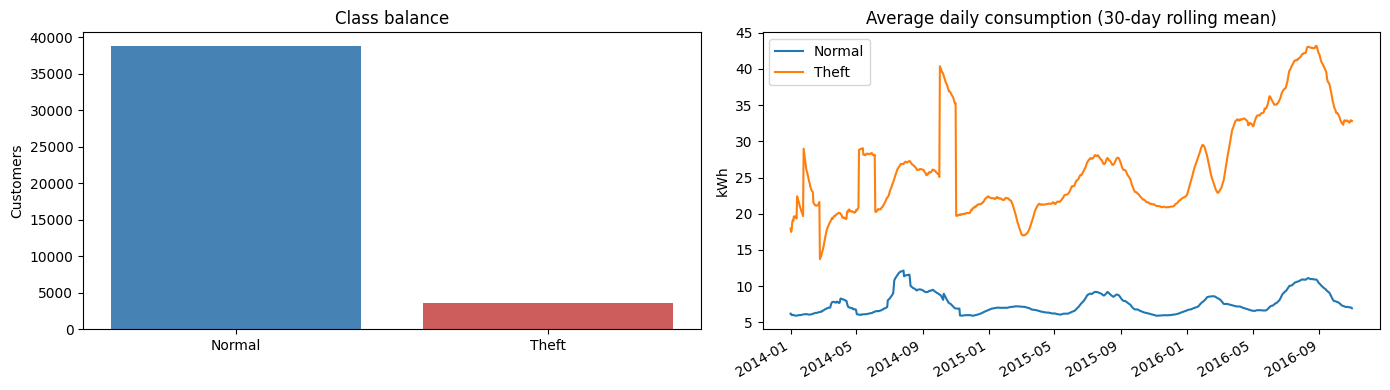

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].bar(['Normal', 'Theft'], np.bincount(y), color=['steelblue', 'indianred'])
ax[0].set_title('Class balance')
ax[0].set_ylabel('Customers')

X_raw.loc[y == 0].mean().rolling(30, min_periods=1).mean().plot(ax=ax[1], label='Normal')
X_raw.loc[y == 1].mean().rolling(30, min_periods=1).mean().plot(ax=ax[1], label='Theft')
ax[1].set_title('Average daily consumption (30-day rolling mean)')
ax[1].set_ylabel('kWh')
ax[1].legend()
plt.tight_layout()
plt.show()

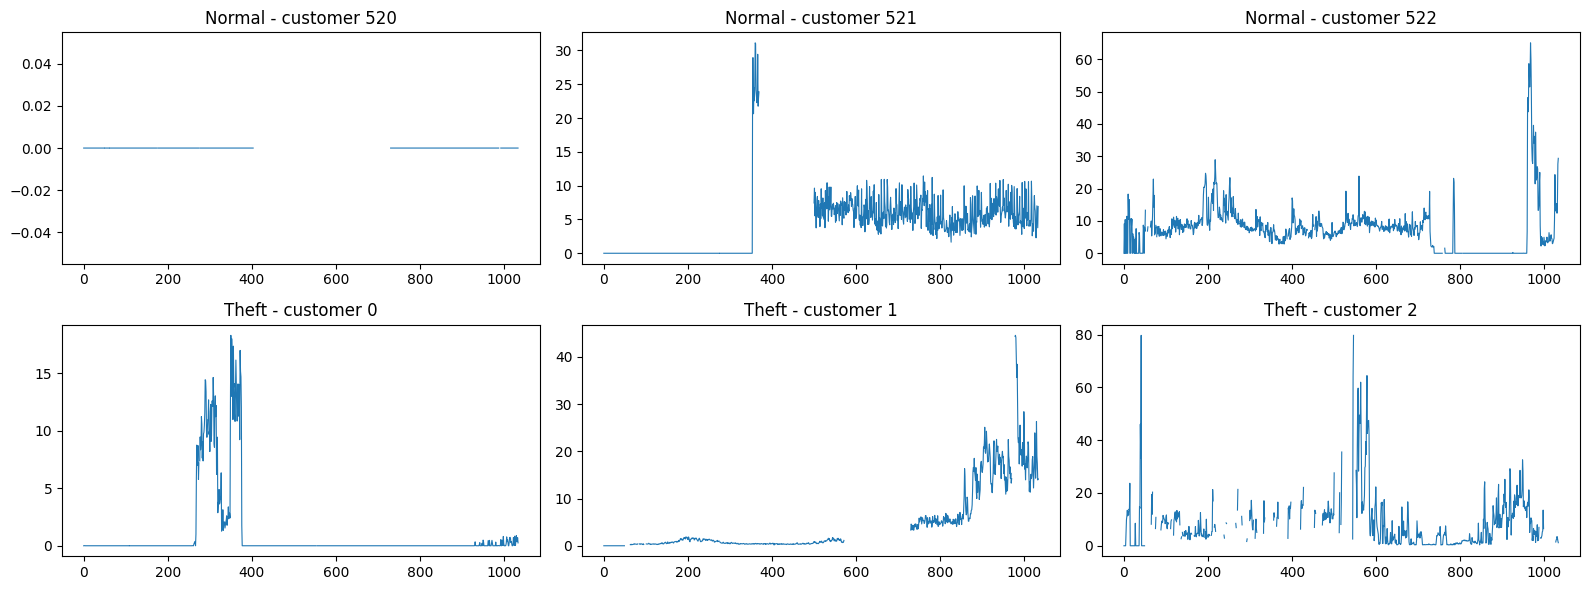

In [ ]:
# Look at individual customers: 3 normal and 3 theft
fig, axes = plt.subplots(2, 3, figsize=(16, 6), sharey=False)
samples = list(np.where(y == 0)[0][:3]) + list(np.where(y == 1)[0][:3])
for a, i in zip(axes.ravel(), samples):
    a.plot(X_raw.iloc[i].values, lw=0.8)
    a.set_title(('Theft' if y[i] == 1 else 'Normal') + f' - customer {i}')
plt.tight_layout()
plt.show()

## Step 3: Clean the data
Cleaning steps: remove duplicate customers, treat negative readings as missing, drop customers with mostly missing data, interpolate short gaps, fill long gaps with the customer's median, and cap extreme outliers.

In [ ]:
X = X_raw.copy()
n_start = len(X)

# 1. Remove duplicate customer IDs
keep = ~pd.Series(ids).duplicated().values
print('Duplicate customers removed:', int((~keep).sum()))

# 2. Negative readings are invalid, so treat them as missing
X = X.mask(X < 0)

# 3. Drop customers with more than 50% missing readings
miss = X.isna().mean(axis=1).values
too_missing = miss > 0.5
print('Customers dropped for >50% missing data:', int(too_missing.sum()))
keep &= ~too_missing

X = X.loc[keep].reset_index(drop=True)
y = y[keep]
ids = ids[keep]

# 4. Fill short gaps (up to 7 days) by linear interpolation along each customer's time series
X = X.interpolate(axis=1, limit=7, limit_direction='both')

# 5. Fill any remaining long gaps with that customer's median
arr = X.to_numpy(dtype=float, copy=True)
row_median = np.nanmedian(arr, axis=1)
rows, cols = np.where(np.isnan(arr))
arr[rows, cols] = row_median[rows]

# 6. Cap extreme outliers at each customer's 99th percentile
cap = np.percentile(arr, 99, axis=1)
arr = np.minimum(arr, cap[:, None])

print('Remaining NaN values:', int(np.isnan(arr).sum()))
X_clean = pd.DataFrame(arr, columns=X.columns)
print(f'Customers: {n_start} -> {len(X_clean)} | Theft rate: {y.mean():.1%}')

Duplicate customers removed: 0
Customers dropped for >50% missing data: 11184
Remaining NaN values: 0
Customers: 42372 -> 31188 | Theft rate: 7.7%


## Step 4: Engineer features
Each customer's time series becomes one row of behavioural features. These features use no labels, so computing the population curve on all customers does not leak the target.

In [ ]:
def longest_run(b):
    # Length of the longest run of consecutive True values
    p = np.concatenate(([0], b.astype(int), [0]))
    d = np.diff(p)
    starts, ends = np.where(d == 1)[0], np.where(d == -1)[0]
    return (ends - starts).max() if len(starts) else 0

A = X_clean.to_numpy()
n, T = A.shape
t = np.arange(T)
mean, std = A.mean(1), A.std(1)

feat = pd.DataFrame({
    'mean': mean,
    'median': np.median(A, 1),
    'std': std,
    'max': A.max(1),
    'min': A.min(1),
    'cv': std / (mean + 1e-6),
    'zero_ratio': (A == 0).mean(1),
    'low_ratio': (A < 0.5 * mean[:, None]).mean(1),
    'longest_zero_run': np.apply_along_axis(longest_run, 1, A == 0),
    'longest_low_run': np.apply_along_axis(longest_run, 1, A < 0.5 * mean[:, None]),
})

# Weekday vs weekend behaviour
weekday = X_clean.columns.dayofweek.values < 5
feat['wkday_wkend_ratio'] = A[:, weekday].mean(1) / (A[:, ~weekday].mean(1) + 1e-6)

# Average consumption in each calendar month (seasonality)
month = X_clean.columns.month.values
for m in range(1, 13):
    feat[f'month_{m}_mean'] = A[:, month == m].mean(1)

# Trend: slope of consumption over time, and last quarter vs first quarter
tc = t - t.mean()
feat['trend_slope'] = ((A - mean[:, None]) * tc).sum(1) / (tc ** 2).sum()
q = T // 4
feat['last_vs_first_quarter'] = A[:, -q:].mean(1) / (A[:, :q].mean(1) + 1e-6)

# Comparison with the average customer
pop = A.mean(0)
pop_c = pop - pop.mean()
num = ((A - mean[:, None]) * pop_c).sum(1)
den = np.sqrt(((A - mean[:, None]) ** 2).sum(1)) * np.sqrt((pop_c ** 2).sum()) + 1e-9
feat['corr_with_population'] = num / den
feat['mean_abs_dev_population'] = np.abs(A - pop).mean(1)
feat['ratio_to_population_mean'] = mean / (pop.mean() + 1e-6)

print('Feature table:', feat.shape, '| NaNs:', int(feat.isna().sum().sum()))
feat.head()

Feature table: (31188, 28) | NaNs: 0


,mean,median,std,max,min,cv,zero_ratio,low_ratio,longest_zero_run,longest_low_run,wkday_wkend_ratio,month_1_mean,month_2_mean,month_3_mean,month_4_mean,month_5_mean,month_6_mean,month_7_mean,month_8_mean,month_9_mean,month_10_mean,month_11_mean,month_12_mean,trend_slope,last_vs_first_quarter,corr_with_population,mean_abs_dev_population,ratio_to_population_mean
0,0.932335,0.000,3.009189,14.40360,0.0,3.227579,0.836557,0.878143,553,573,0.948633,1.517858,0.000000,0.000000,0.000000,0.000000,0.000000,0.008280,0.036022,0.479326,3.435469,3.500393,3.976961,-0.001898,1.707935e+03,-0.035247,8.214707,0.107975
1,4.040757,0.945,6.487928,29.00635,0.0,1.605622,0.048356,0.699226,50,723,0.958843,1.657849,1.933187,1.976281,2.014833,3.347581,6.108667,6.772769,6.237983,8.503144,6.089516,0.709333,0.931332,0.015702,2.093094e+01,0.451877,6.958927,0.467964
2,8.410939,6.300,8.838134,51.42280,0.0,1.050790,0.032882,0.345261,12,55,0.899218,4.778817,6.154937,7.604550,7.040667,9.286452,10.648253,18.482630,12.632372,6.278323,5.325261,4.639667,5.489516,-0.000373,1.093618e+00,0.331893,5.750330,0.974078
3,3.745740,0.000,7.914723,34.33050,0.0,2.112992,0.773694,0.773694,800,800,0.932060,0.000000,0.000000,1.990000,3.316222,3.675376,3.834889,8.657677,9.217543,5.882697,5.555484,0.000000,0.000000,0.017540,1.501200e+07,0.454656,8.050345,0.433798
4,8.250385,6.050,8.000908,37.13030,0.0,0.969762,0.142166,0.338491,10,14,1.624729,7.458710,3.854118,13.940497,9.462056,7.901828,11.264337,10.717097,10.874105,7.061910,4.610161,4.323500,4.649677,0.007918,2.154008e+00,0.330554,5.794979,0.955485


In [ ]:
# Which features separate theft from normal customers?
comparison = feat.assign(FLAG=y).groupby('FLAG')[['mean', 'std', 'zero_ratio', 'low_ratio',
                                                    'longest_zero_run', 'trend_slope',
                                                    'corr_with_population']].mean().T
comparison.columns = ['Normal', 'Theft']
comparison

,Normal,Theft
mean,7.390061,23.504548
std,4.891836,15.958448
zero_ratio,0.181215,0.117613
low_ratio,0.230539,0.282993
longest_zero_run,117.309323,55.092985
trend_slope,0.000928,0.011595
corr_with_population,0.203269,0.249741


## Step 5: Split the data by customer
Each customer is one row, so a stratified split guarantees no customer appears in two sets. The anomaly score is fitted on the **training set only**.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest

idx = np.arange(len(feat))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=RANDOM_STATE)

X_train, X_val, X_test = feat.iloc[idx_train].copy(), feat.iloc[idx_val].copy(), feat.iloc[idx_test].copy()
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]

# Unsupervised anomaly score as an extra feature (fitted on training data only)
iso = IsolationForest(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train)
for d in (X_train, X_val, X_test):
    d['anomaly_score'] = -iso.score_samples(d)

for name, yy in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f'{name:<11} n={len(yy):>6} | theft={yy.sum():>5} ({yy.mean():.1%})')

Train       n= 21831 | theft= 1686 (7.7%)
Validation  n=  4678 | theft=  361 (7.7%)
Test        n=  4679 | theft=  362 (7.7%)


## Step 6: Train and compare models
Baseline (Logistic Regression), Random Forest, XGBoost, LightGBM, and SMOTE + Random Forest (SMOTE is applied inside the pipeline, so it only ever touches training data).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score)

neg, pos = np.bincount(y_train)
spw = neg / pos
print(f'Class ratio (normal:theft) = {spw:.1f}:1')

def precision_at_k(y_true, scores, k):
    # Share of real thieves among the k highest-risk customers
    top = np.argsort(-scores)[:k]
    return y_true[top].mean()

def evaluate(name, scores, y_true, thr=0.5):
    pred = (scores >= thr).astype(int)
    return {
        'Model': name,
        'ROC-AUC': roc_auc_score(y_true, scores),
        'PR-AUC': average_precision_score(y_true, scores),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred),
        'F1': f1_score(y_true, pred),
        'P@100': precision_at_k(y_true, scores, 100),
        'P@500': precision_at_k(y_true, scores, 500),
    }

Class ratio (normal:theft) = 11.9:1


In [ ]:
models = {
    'Logistic Regression': Pipeline([('scale', StandardScaler()),
                                     ('clf', LogisticRegression(class_weight='balanced', max_iter=2000))]),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                            n_jobs=-1, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=spw, eval_metric='aucpr',
                             tree_method='hist', n_jobs=-1, random_state=RANDOM_STATE),
    'LightGBM': LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                               scale_pos_weight=spw, random_state=RANDOM_STATE, verbose=-1),
    'SMOTE + Random Forest': ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                                          ('clf', RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                                                         random_state=RANDOM_STATE))]),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    scores = model.predict_proba(X_val)[:, 1]
    results.append(evaluate(name, scores, y_val))
    print('Finished:', name)

results_df = pd.DataFrame(results).set_index('Model').sort_values('PR-AUC', ascending=False)
results_df.round(3)

Finished: Logistic Regression
Finished: Random Forest
Finished: XGBoost
Finished: LightGBM
Finished: SMOTE + Random Forest


,ROC-AUC,PR-AUC,Precision,Recall,F1,P@100,P@500
Model,,,,,,,
XGBoost,0.794,0.333,0.251,0.518,0.338,0.51,0.304
LightGBM,0.781,0.326,0.269,0.443,0.335,0.52,0.296
Random Forest,0.768,0.325,0.625,0.083,0.147,0.57,0.298
SMOTE + Random Forest,0.776,0.307,0.329,0.380,0.353,0.54,0.294
Logistic Regression,0.733,0.243,0.161,0.607,0.255,0.40,0.238


**1D-CNN on the raw daily sequences.**

In [ ]:
import tensorflow as tf
from tensorflow import keras

def prep_seq(i):
    s = A[i]
    s = s / (s.max(axis=1, keepdims=True) + 1e-6)   # scale each customer to 0-1
    return s[..., None].astype('float32')

S_train, S_val, S_test = prep_seq(idx_train), prep_seq(idx_val), prep_seq(idx_test)

cnn = keras.Sequential([
    keras.layers.Input(shape=(T, 1)),
    keras.layers.Conv1D(32, 7, activation='relu'),
    keras.layers.MaxPooling1D(2),
    keras.layers.Conv1D(64, 5, activation='relu'),
    keras.layers.MaxPooling1D(2),
    keras.layers.Conv1D(64, 3, activation='relu'),
    keras.layers.GlobalAveragePooling1D(),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation='sigmoid'),
])
cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
            metrics=[keras.metrics.AUC(name='auc'), keras.metrics.AUC(curve='PR', name='pr_auc')])

cnn.fit(S_train, y_train, validation_data=(S_val, y_val), epochs=15, batch_size=128,
        class_weight={0: 1.0, 1: float(spw)}, verbose=2)

cnn_scores = cnn.predict(S_val, verbose=0).ravel()
results_df.loc['1D-CNN'] = pd.Series(evaluate('1D-CNN', cnn_scores, y_val)).drop('Model')
results_df.sort_values('PR-AUC', ascending=False).round(3)

Epoch 1/15
171/171 - 54s - 314ms/step - auc: 0.5665 - loss: 1.2660 - pr_auc: 0.0913 - val_auc: 0.6664 - val_loss: 0.6365 - val_pr_auc: 0.1267
Epoch 2/15
171/171 - 50s - 294ms/step - auc: 0.6356 - loss: 1.2285 - pr_auc: 0.1141 - val_auc: 0.6783 - val_loss: 0.7583 - val_pr_auc: 0.1327
Epoch 3/15
171/171 - 51s - 297ms/step - auc: 0.6564 - loss: 1.2090 - pr_auc: 0.1294 - val_auc: 0.6953 - val_loss: 0.5881 - val_pr_auc: 0.1488
Epoch 4/15
171/171 - 81s - 471ms/step - auc: 0.6715 - loss: 1.1935 - pr_auc: 0.1327 - val_auc: 0.7057 - val_loss: 0.5823 - val_pr_auc: 0.1607
Epoch 5/15
171/171 - 83s - 487ms/step - auc: 0.6834 - loss: 1.1815 - pr_auc: 0.1455 - val_auc: 0.7083 - val_loss: 0.6350 - val_pr_auc: 0.1695
Epoch 6/15
171/171 - 80s - 471ms/step - auc: 0.6889 - loss: 1.1728 - pr_auc: 0.1573 - val_auc: 0.7156 - val_loss: 0.5658 - val_pr_auc: 0.1749
Epoch 7/15
171/171 - 51s - 298ms/step - auc: 0.6968 - loss: 1.1688 - pr_auc: 0.1637 - val_auc: 0.7199 - val_loss: 0.5860 - val_pr_auc: 0.1798
Epoch 

,ROC-AUC,PR-AUC,Precision,Recall,F1,P@100,P@500
Model,,,,,,,
XGBoost,0.794,0.333,0.251,0.518,0.338,0.51,0.304
LightGBM,0.781,0.326,0.269,0.443,0.335,0.52,0.296
Random Forest,0.768,0.325,0.625,0.083,0.147,0.57,0.298
SMOTE + Random Forest,0.776,0.307,0.329,0.380,0.353,0.54,0.294
Logistic Regression,0.733,0.243,0.161,0.607,0.255,0.40,0.238
1D-CNN,0.751,0.239,0.158,0.651,0.254,0.41,0.268


In [ ]:
# Save the comparison table
results_df.round(4).to_csv('model_comparison_validation.csv')

## Step 7: Tune and evaluate
Tune XGBoost with stratified 5-fold cross-validation, optimising PR-AUC (not accuracy). Choose the decision threshold on the validation set, then evaluate **once** on the test set.

In [ ]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

param_dist = {
    'n_estimators': [200, 400, 600],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.3],
}

search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=spw, eval_metric='aucpr', tree_method='hist',
                  n_jobs=-1, random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=20,                       # lower to 10 if it runs too slowly
    scoring='average_precision',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=1, verbose=1, random_state=RANDOM_STATE,
)
search.fit(X_train, y_train)

best = search.best_estimator_
print('Best parameters:', search.best_params_)
print('Best cross-validated PR-AUC:', round(search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters: {'subsample': 0.6, 'n_estimators': 600, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.03, 'gamma': 0, 'colsample_bytree': 1.0}
Best cross-validated PR-AUC: 0.366


Chosen threshold: 0.673
              precision    recall  f1-score   support

      Normal      0.950     0.940     0.945      4317
       Theft      0.361     0.406     0.382       362

    accuracy                          0.898      4679
   macro avg      0.655     0.673     0.664      4679
weighted avg      0.904     0.898     0.901      4679

ROC-AUC: 0.811
PR-AUC : 0.3478


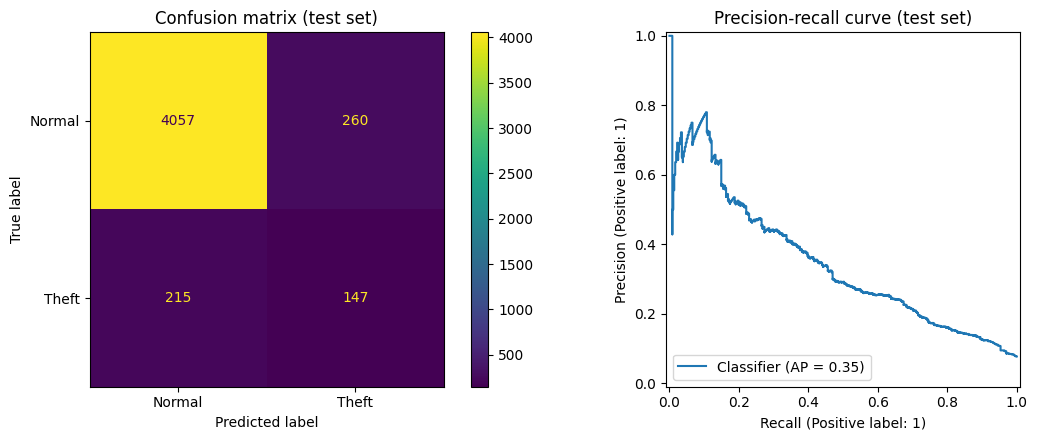

In [ ]:
from sklearn.metrics import (precision_recall_curve, classification_report,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)

# Choose the threshold that maximises F1 on the VALIDATION set
s_val = best.predict_proba(X_val)[:, 1]
p, r, th = precision_recall_curve(y_val, s_val)
f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-9)
thr = float(th[np.argmax(f1)])
print('Chosen threshold:', round(thr, 3))

# Final evaluation on the untouched TEST set
s_test = best.predict_proba(X_test)[:, 1]
pred_test = (s_test >= thr).astype(int)

print(classification_report(y_test, pred_test, target_names=['Normal', 'Theft'], digits=3))
print('ROC-AUC:', round(roc_auc_score(y_test, s_test), 4))
print('PR-AUC :', round(average_precision_score(y_test, s_test), 4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=['Normal', 'Theft'], ax=ax[0])
PrecisionRecallDisplay.from_predictions(y_test, s_test, ax=ax[1])
ax[0].set_title('Confusion matrix (test set)')
ax[1].set_title('Precision-recall curve (test set)')
plt.tight_layout()
plt.show()

In [ ]:
# Precision@k: if the utility can only inspect k customers, how many are real thieves?
base_rate = y_test.mean()
rows = []
for k in (50, 100, 200, 500):
    pk = precision_at_k(y_test, s_test, k)
    rows.append({'Inspections (k)': k, 'Precision@k': round(pk, 3),
                 'Random inspection': round(base_rate, 3), 'Lift': round(pk / base_rate, 1)})
pd.DataFrame(rows)

,Inspections (k),Precision@k,Random inspection,Lift
0,50,0.780,0.077,10.1
1,100,0.560,0.077,7.2
2,200,0.475,0.077,6.1
3,500,0.330,0.077,4.3


## Step 8: Explain the model

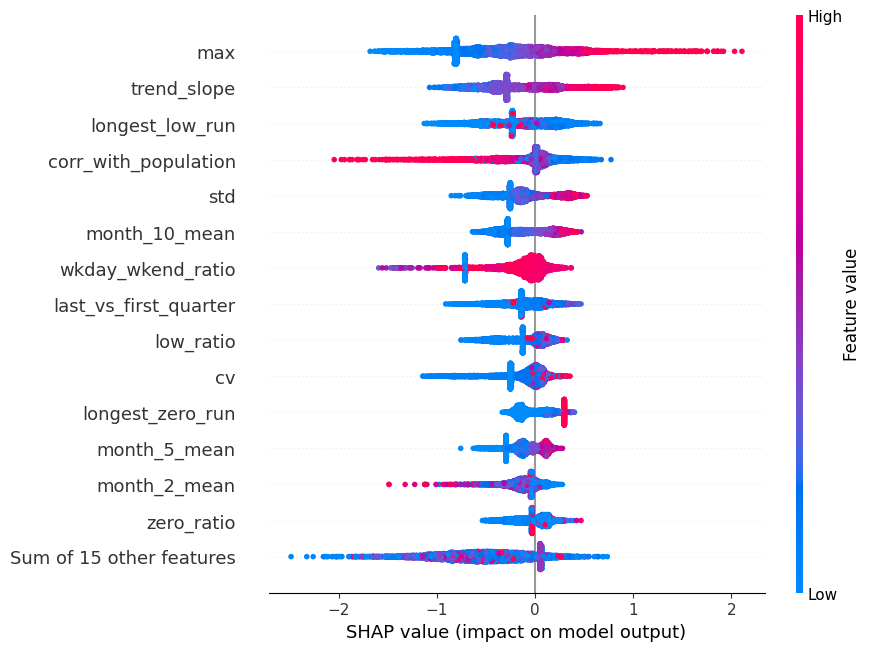

In [ ]:
import shap

explainer = shap.TreeExplainer(best)
sv = explainer(X_test)

# Global view: which behaviours drive theft predictions overall
shap.plots.beeswarm(sv, max_display=15)

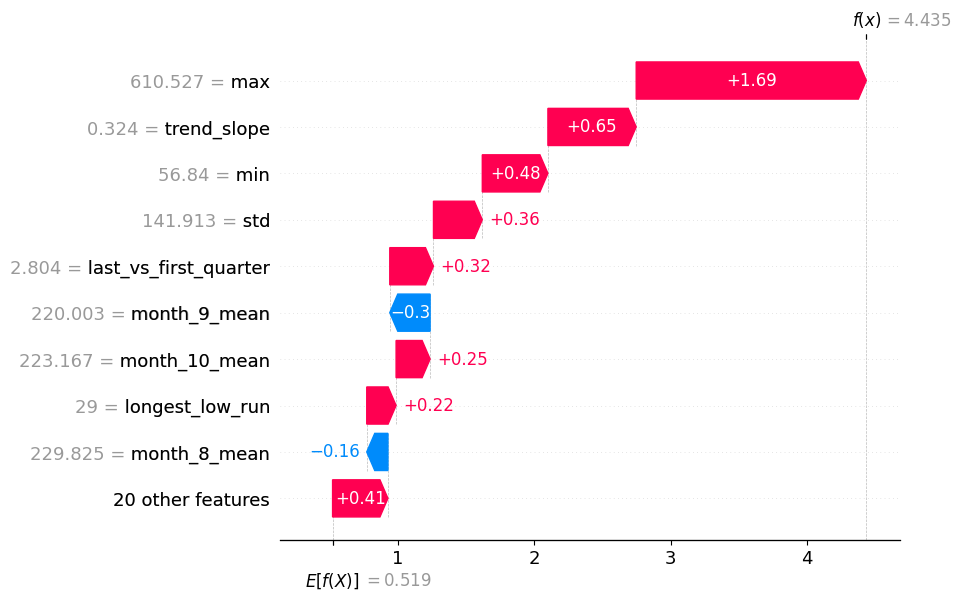

In [ ]:
# Local view: why was the highest-risk customer flagged?
top_customer = int(np.argmax(s_test))
shap.plots.waterfall(sv[top_customer], max_display=10)